$$\LARGE Упражнение \ по \ программированию \ 2: \ Логистическая \ регрессия $$
$$\large Машинное \ обучение $$
## Введение

В этом упражнении вы реализуете логистическую регрессию и примените её к двум разным наборам данных. Перед началом практического задания настоятельно рекомендуется посмотреть видеолекции и ответить на контрольные вопросы по соответствующим темам.

Чтобы приступить к выполнению упражнения, необходимо скачать стартовый код и распаковать его содержимое в каталог, в котором вы планируете работать. При необходимости используйте команду `cd` в Octave, чтобы перейти в этот каталог перед началом работы.

Инструкции по установке Octave также можно найти на странице *Octave Installation* на сайте курса.

### Файлы, включённые в упражнение

* `ex2.m` — скрипт Octave, который поможет пошагово пройти упражнение
* `ex2 reg.m` — скрипт Octave для последующих частей упражнения
* `ex2data1.txt` — обучающая выборка для первой половины упражнения
* `ex2data2.txt` — обучающая выборка для второй половины упражнения
* `submit.m` — скрипт отправки решений на сервер
* `mapFeature.m` — функция генерации полиномиальных признаков
* `plotDecisionBounday.m` — функция построения границы решения классификатора
*  `plotData.m` — функция построения графика двумерных данных классификации
*  `sigmoid.m` — сигмоидная функция
*  `costFunction.m` — функция стоимости логистической регрессии
*  `predict.m` — функция предсказания логистической регрессии
*  `costFunctionReg.m` — регуляризованная функция стоимости логистической регрессии

На протяжении всего упражнения вы будете использовать скрипты `ex2.m` и `ex2 reg.m`. Эти скрипты подготавливают наборы данных для задач и вызывают функции, которые вы напишете. Изменять ни один из этих двух скриптов не требуется — нужно изменять только функции в других файлах в соответствии с инструкциями задания.

In [ ]:
cd('resources/5-lab');

## 1 Логистическая регрессия

В этой части упражнения вы построите модель логистической регрессии для предсказания того, поступит ли студент в университет.

Представьте, что вы администратор университетского факультета и хотите определить вероятность поступления каждого абитуриента по результатам двух экзаменов. У вас есть исторические данные прошлых абитуриентов, которые можно использовать в качестве обучающей выборки для логистической регрессии. Для каждого обучающего примера известны баллы абитуриента за два экзамена и решение о зачислении.

Ваша задача — построить классификационную модель, оценивающую вероятность поступления абитуриента на основе баллов за эти два экзамена. Данное описание и каркасный код в `ex2.m` проведут вас через выполнение упражнения.

### 1.1 Визуализация данных

Прежде чем реализовывать любой алгоритм обучения, по возможности всегда полезно визуализировать данные. В первой части `ex2.m` код загрузит данные и отобразит их на двумерном графике с помощью вызова функции `plotData`.

Теперь вам нужно дописать код в `plotData`, чтобы он строил график, похожий на рисунок 1, где по осям отложены баллы за два экзамена, а положительные и отрицательные примеры обозначены разными маркерами.

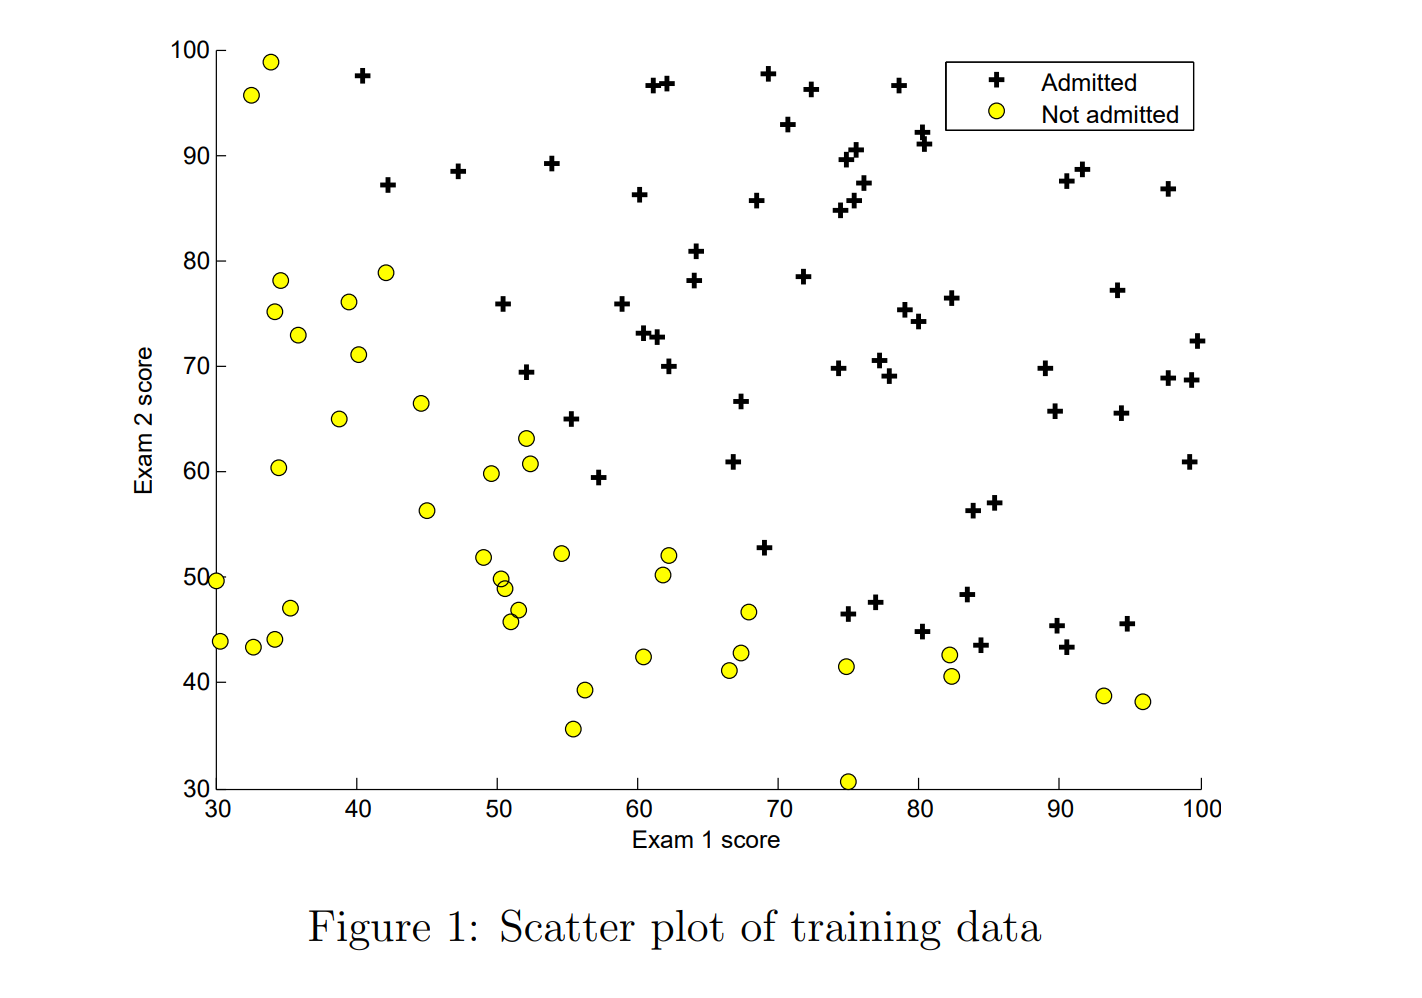

Чтобы вы могли лучше освоить построение графиков, мы оставили `plotData.m` пустым, чтобы вы попробовали реализовать его самостоятельно. Однако это необязательное (не оцениваемое) упражнение. Ниже мы также приводим нашу реализацию, которую вы можете скопировать или использовать как ориентир. Если вы решите скопировать наш пример, обязательно разберитесь, что делает каждая команда, обратившись к документации Octave.

``` octave
% Find Indices of Positive and Negative Examples
pos = find(y==1); neg = find(y == 0);
% Plot Examples
plot(X(pos, 1), X(pos, 2), 'k+','LineWidth', 2, ...
'MarkerSize', 7);
plot(X(neg, 1), X(neg, 2), 'ko', 'MarkerFaceColor', 'y', ...
'MarkerSize', 7);
```

In [ ]:
data = load('ex2data1.txt');
X = data(:, [1, 2]); y = data(:, 3);

plotData(X, y);

### 1.2 Реализация

#### 1.2.1 Разминочное упражнение: сигмоидная функция

Прежде чем переходить к самой функции стоимости, вспомним, что гипотеза логистической регрессии определяется как:

$$h_\theta(x) = g(\theta^T x)$$

где функция $g$ — это сигмоидная функция. Сигмоидная функция определяется как:

$$g(z) = \frac{1}{1 + e^{-z}}$$

Ваш первый шаг — реализовать эту функцию в `sigmoid.m`, чтобы её могла вызывать остальная часть программы. Когда закончите, попробуйте проверить несколько значений, вызвав `sigmoid(x)` в командной строке Octave. Для больших положительных значений $x$ сигмоида должна быть близка к $1$, а для больших отрицательных значений — близка к $0$. Вычисление `sigmoid(0)` должно давать ровно $0.5$. Ваш код также должен работать с векторами и матрицами. Для матрицы функция должна применять сигмоиду к каждому элементу.

Вы можете отправить решение на проверку, введя `submit` в командной строке Octave. Скрипт отправки запросит ваше имя пользователя и пароль, а также спросит, какие файлы вы хотите отправить. Пароль для отправки можно получить на сайте.

In [ ]:
sigmoid(0.708)

#### 1.2.2 Функция стоимости и градиент

Теперь вам предстоит реализовать функцию стоимости и градиент для логистической регрессии. Допишите код в `costFunction.m`, чтобы функция возвращала значение стоимости и градиент.

Вспомним, что функция стоимости в логистической регрессии имеет вид:

$$J(\theta) = \frac{1}{m} \sum_{i=1}^{m} \left[ -y^{(i)} \log\left(h_\theta(x^{(i)})\right) - (1 - y^{(i)}) \log\left(1 - h_\theta(x^{(i)})\right) \right]$$

а градиент функции стоимости представляет собой вектор той же размерности, что и $\theta$, где $j$-й элемент (для $j = 0, 1, \dots, n$) определяется следующим образом:

$$\frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{m} \sum_{i=1}^{m} \left(h_\theta(x^{(i)}) - y^{(i)}\right) x_j^{(i)}$$

Обратите внимание: хотя эта формула градиента выглядит идентично градиенту линейной регрессии, на самом деле она отличается, поскольку в линейной и логистической регрессии функция $h_\theta(x)$ определяется по-разному.

Когда вы закончите, скрипт `ex2.m` вызовет вашу функцию `costFunction` с начальными параметрами $\theta$. Вы должны увидеть, что значение стоимости составляет около `0.693`.

Теперь вы можете отправить функцию стоимости и градиент для логистической регрессии. Сделайте две отправки: одну для функции стоимости и одну для градиента.

#### 1.2.3 Подбор параметров с помощью `fminunc`

В предыдущем задании вы находили оптимальные параметры модели линейной регрессии, реализуя градиентный спуск: вы писали функцию стоимости, вычисляли её градиент и затем делали шаг градиентного спуска. На этот раз вместо шагов градиентного спуска вы воспользуетесь встроенной функцией Octave под названием `fminunc`.

`fminunc` в Octave — это оптимизационный решатель, который находит минимум функции без ограничений. Для логистической регрессии вам нужно минимизировать функцию стоимости $J(\theta)$ по параметрам $\theta$.

Конкретно вы будете использовать `fminunc`, чтобы найти наилучшие параметры $\theta$ для функции стоимости логистической регрессии на фиксированном наборе данных (`X` и `y`). В `fminunc` передаются следующие входные данные:

* Начальные значения параметров, которые мы хотим оптимизировать.
* Функция, которая при заданной обучающей выборке и конкретном $\theta$ вычисляет стоимость логистической регрессии и градиент по $\theta$ для набора данных `(X, y)`.

В `ex2.m` уже написан код, который вызывает `fminunc` с нужными аргументами:

```octave
% Set options for fminunc
options = optimset('GradObj', 'on', 'MaxIter', 400);

% Run fminunc to obtain the optimal theta
% This function will return theta and the cost
[theta, cost] = ...
fminunc(@(t)(costFunction(t, X, y)), initial theta, options);

```

В этом фрагменте кода сначала задаются параметры работы `fminunc`. В частности, опция `'GradObj'` устанавливается в `'on'`, что сообщает `fminunc`, будто наша функция возвращает и стоимость, и градиент — это позволяет решателю использовать градиент при минимизации. Кроме того, опция `'MaxIter'` задаётся равной `400`, чтобы `fminunc` выполнил не более 400 шагов до остановки.

Чтобы указать саму минимизируемую функцию, используется краткая форма записи анонимной функции: `@(t) ( costFunction(t, X, y) )`. Она создаёт функцию с аргументом `t`, которая вызывает ваш `costFunction`. Это позволяет обернуть `costFunction` для передачи в `fminunc`.

Если вы реализовали `costFunction` правильно, `fminunc` сойдётся к верным оптимизированным параметрам и вернёт итоговые значения стоимости и $\theta$. Заметьте, что при использовании `fminunc` вам не пришлось самостоятельно писать циклы или задавать скорость обучения ($\alpha$), как в градиентном спуске: всё это берёт на себя `fminunc`, а от вас требуется только функция, вычисляющая стоимость и градиент.

После завершения работы `fminunc` скрипт `ex2.m` вызовет вашу функцию `costFunction` с найденными оптимальными параметрами $\theta$. Вы должны увидеть значение стоимости около `0.203`.

Это итоговое значение $\theta$ затем будет использовано для построения границы решения на обучающих данных, в результате чего получится график, похожий на рисунок 2. Мы также рекомендуем посмотреть код в `plotDecisionBoundary.m`, чтобы увидеть, как строится такая граница с использованием значений $\theta$.

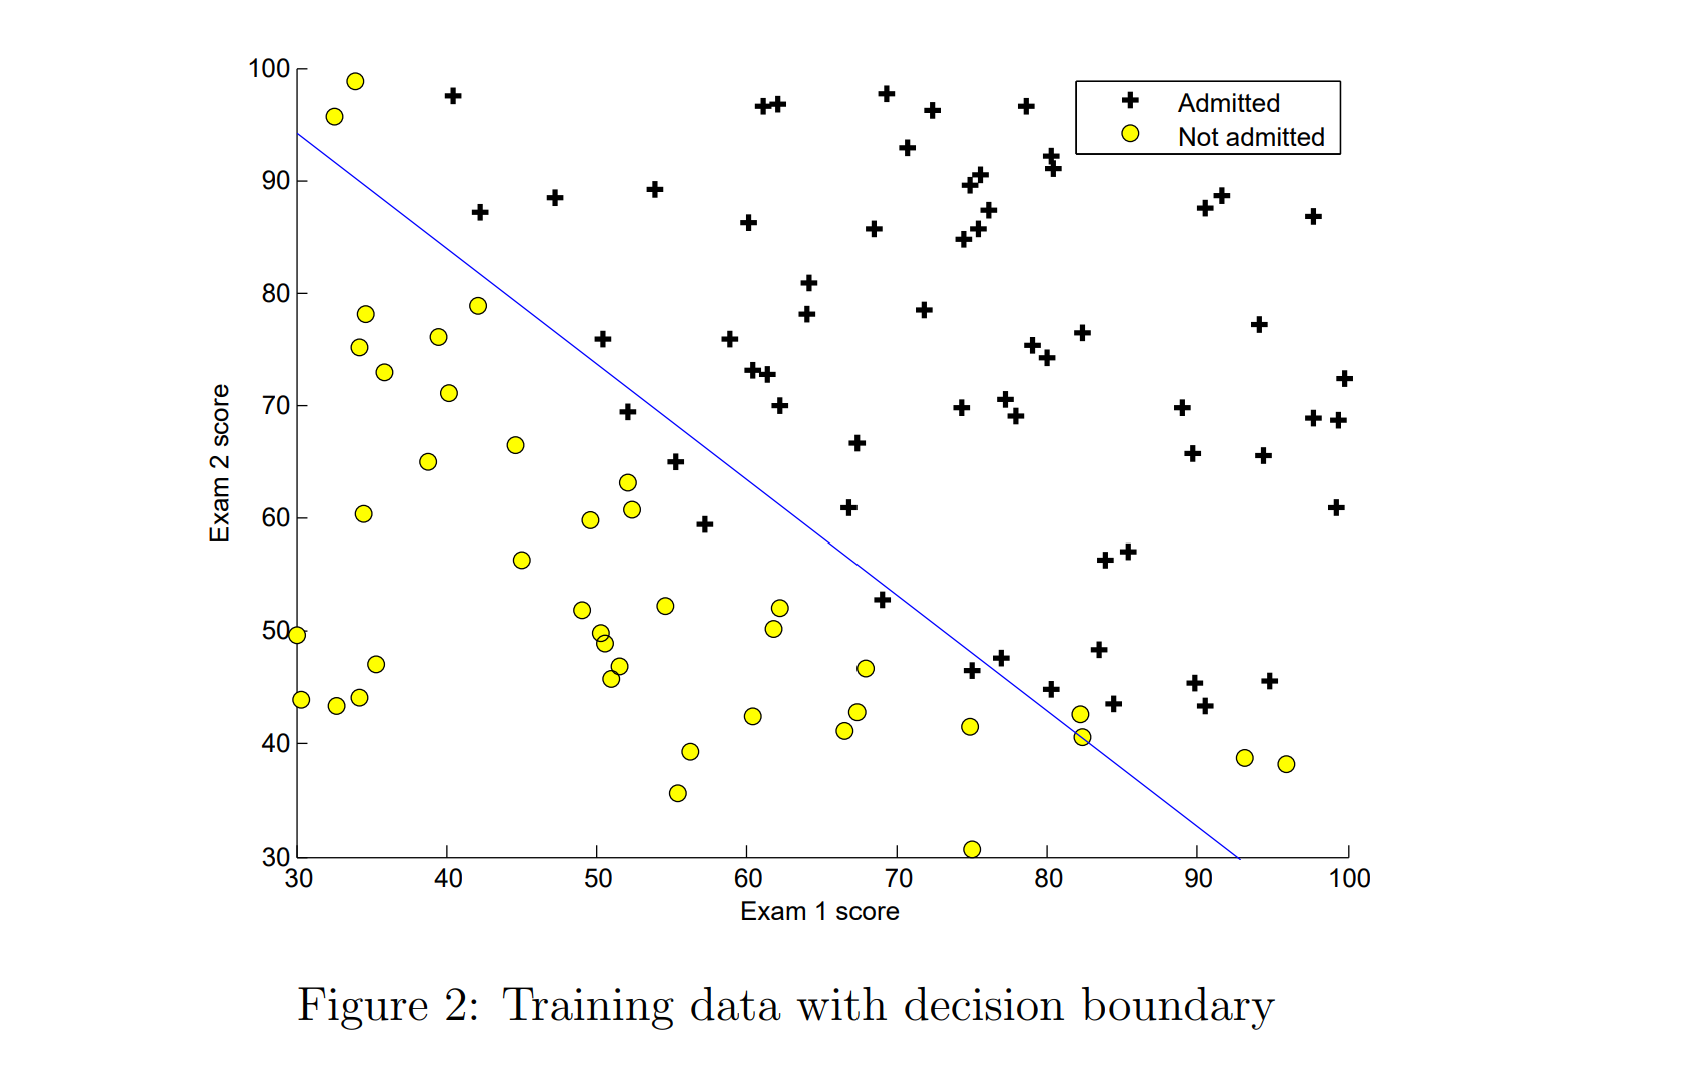



#### 1.2.4 Оценка качества логистической регрессии

После обучения параметров модель можно использовать для предсказания того, поступит ли конкретный студент. Для абитуриента с баллами `45` за первый экзамен и `85` за второй вы должны получить вероятность поступления около `0.776`.

Другой способ оценить качество найденных параметров — посмотреть, насколько хорошо обученная модель предсказывает значения на обучающей выборке. В этой части ваша задача — дописать код в `predict.m`. Функция `predict` должна возвращать предсказания `1` или `0` для заданного набора данных и обученного вектора параметров $\theta$.

После того как вы завершите код в `predict.m`, скрипт `ex2.m` выведет точность классификатора на обучающей выборке, вычислив процент примеров, на которых модель дала верный ответ.


In [ ]:
ex2()

# 2 Регуляризованная логистическая регрессия

В этой части упражнения вы реализуете регуляризованную логистическую регрессию для предсказания того, пройдут ли микрочипы с производственного завода контроль качества (QA). Во время проверки качества каждый микрочип проходит различные тесты, чтобы убедиться в его исправной работе.

Представьте, что вы продакт-менеджер завода и у вас есть результаты тестирования нескольких микрочипов по двум различным тестам. На основе этих двух тестов вам нужно определить, следует ли принять микрочипы или отбраковать их. Чтобы помочь вам принять решение, у вас есть набор данных с результатами тестов прошлых микрочипов, по которому можно построить модель логистической регрессии.

Для выполнения этой части упражнения вы будете использовать другой скрипт — `ex2_reg.m`.

## 2.1 Визуализация данных

Как и в предыдущих частях этого упражнения, функция `plotData` используется для построения графика, похожего на рисунок 3, где по осям отложены результаты двух тестов, а положительные ($y = 1$, принято) и отрицательные ($y = 0$, отбраковано) примеры обозначены разными маркерами.

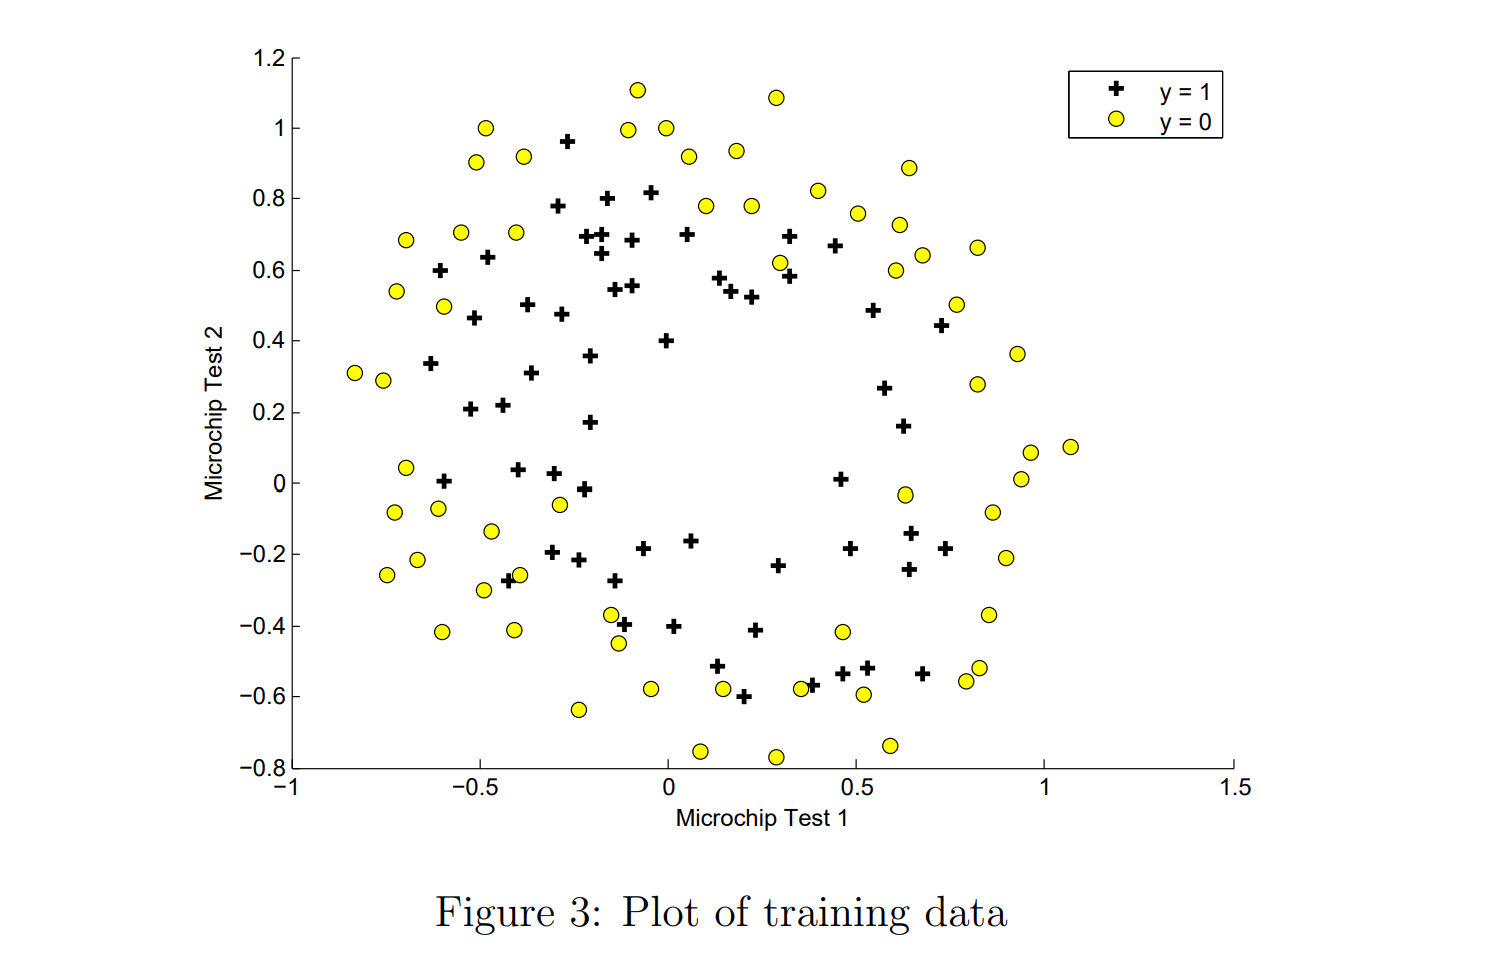

отрицательные примеры прямой линией на графике. Поэтому прямое применение логистической регрессии на этом наборе данных покажет себя плохо, поскольку логистическая регрессия способна провести только линейную границу решения.

### 2.2 Отображение признаков

Один из способов лучше приблизить данные — создать больше признаков из каждой точки данных. В предоставленной функции `mapFeature.m` признаки преобразуются во все полиномиальные члены от $x_1$ и $x_2$ вплоть до шестой степени.

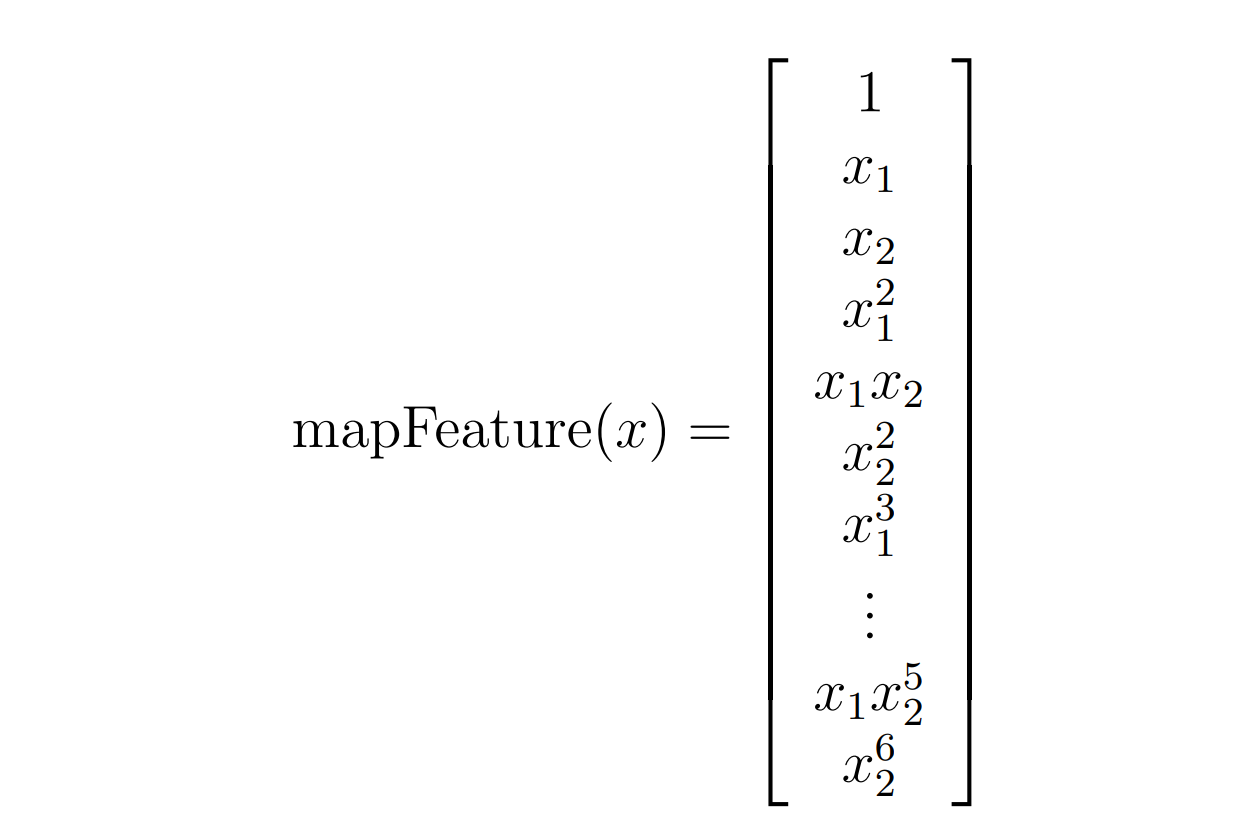

В результате такого отображения вектор из двух признаков (результатов двух тестов контроля качества) преобразуется в 28-мерный вектор. Классификатор логистической регрессии, обученный на этом векторе признаков большей размерности, будет иметь более сложную границу решения и на двумерном графике будет выглядеть нелинейным.

Хотя отображение признаков позволяет построить более выразительный классификатор, оно также делает модель более подверженной переобучению. В следующих частях упражнения вы реализуете регуляризованную логистическую регрессию для подгонки данных и сами увидите, как регуляризация помогает бороться с переобучением.
### 2.3 Функция стоимости и градиент

Теперь вам предстоит реализовать вычисление функции стоимости и градиента для регуляризованной логистической регрессии. Допишите код в `costFunctionReg.m`, чтобы функция возвращала стоимость и градиент.

Вспомним, что регуляризованная функция стоимости в логистической регрессии имеет вид:

$$J(\theta) = \frac{1}{m} \sum_{i=1}^{m} \left[ -y^{(i)} \log\left(h_\theta(x^{(i)})\right) - (1 - y^{(i)}) \log\left(1 - h_\theta(x^{(i)})\right) \right] + \frac{\lambda}{2m} \sum_{j=1}^{n} \theta_j^2$$

Обратите внимание, что параметр $\theta_0$ регуляризовать не следует; поэтому последняя сумма выше берётся по $j$ от $1$ до $n$, а не от $0$ до $n$. Градиент функции стоимости представляет собой вектор, $j$-й элемент которого определяется следующим образом:

$$\frac{\partial J(\theta)}{\partial \theta_0} = \frac{1}{m} \sum_{i=1}^{m} \left(h_\theta(x^{(i)}) - y^{(i)}\right) x_j^{(i)} \quad \text{для } j = 0$$

$$\frac{\partial J(\theta)}{\partial \theta_j} = \left( \frac{1}{m} \sum_{i=1}^{m} \left(h_\theta(x^{(i)}) - y^{(i)}\right) x_j^{(i)} \right) + \frac{\lambda}{m}\theta_j \quad \text{для } j \ge 1$$

*(Примечание: в тексте оригинала перед $\lambda\theta_j$ пропущен делитель $m$, однако множитель $\frac{1}{m}$ относится ко всему выражению в скобках: $\frac{1}{m}\left(\sum_{i=1}^{m} (h_\theta(x^{(i)}) - y^{(i)}) x_j^{(i)} + \lambda\theta_j\right)$.)*

Когда вы закончите, скрипт `ex2_reg.m` вызовет вашу функцию `costFunctionReg` с начальным значением $\theta$ (инициализированным нулями). Вы должны увидеть, что стоимость составляет около `0.693`.

Теперь вы можете отправить функцию стоимости и градиент для регуляризованной логистической регрессии. Сделайте две отправки: одну для функции стоимости и одну для градиента.

## 2.3.1 Подбор параметров с помощью `fminunc`

Как и в предыдущих частях, вы будете использовать `fminunc` для нахождения оптимальных параметров $\theta$. Если вы правильно реализовали вычисление стоимости и градиента для регуляризованной логистической регрессии (`costFunctionReg.m`), вы сможете выполнить следующую часть скрипта `ex2_reg.m` и обучить параметры $\theta$ с помощью `fminunc`.

## 2.4 Построение границы решения

Чтобы помочь вам визуализировать модель, обученную этим классификатором, мы предоставили функцию `plotDecisionBoundary.m`, которая строит (нелинейную) границу решения, разделяющую положительные и отрицательные примеры. В `plotDecisionBoundary.m` нелинейная граница решения строится путём вычисления предсказаний классификатора на равномерной сетке с последующим построением контурного графика в тех местах, где предсказания меняются с $y = 0$ на $y = 1$.

После нахождения параметров $\theta$ следующий шаг в `ex2_reg.m` построит границу решения, похожую на рисунок 4.

## 2.5 Необязательное упражнение (без оценки): влияние λ

Попробуйте разные значения λ и посмотрите, как меняется граница решения и точность на обучающей выборке:

- **λ = 0** — переобучение: граница очень сложная, почти все примеры классифицируются верно, но граница неправдоподобна (**Картинка тут**).
- **λ = 1** — хороший компромисс (**Картинка тут**).
- **λ = 100** — недообучение: граница слишком простая и не следует за данными (**Картинка тут**).

Отправлять решения для этой части не нужно.

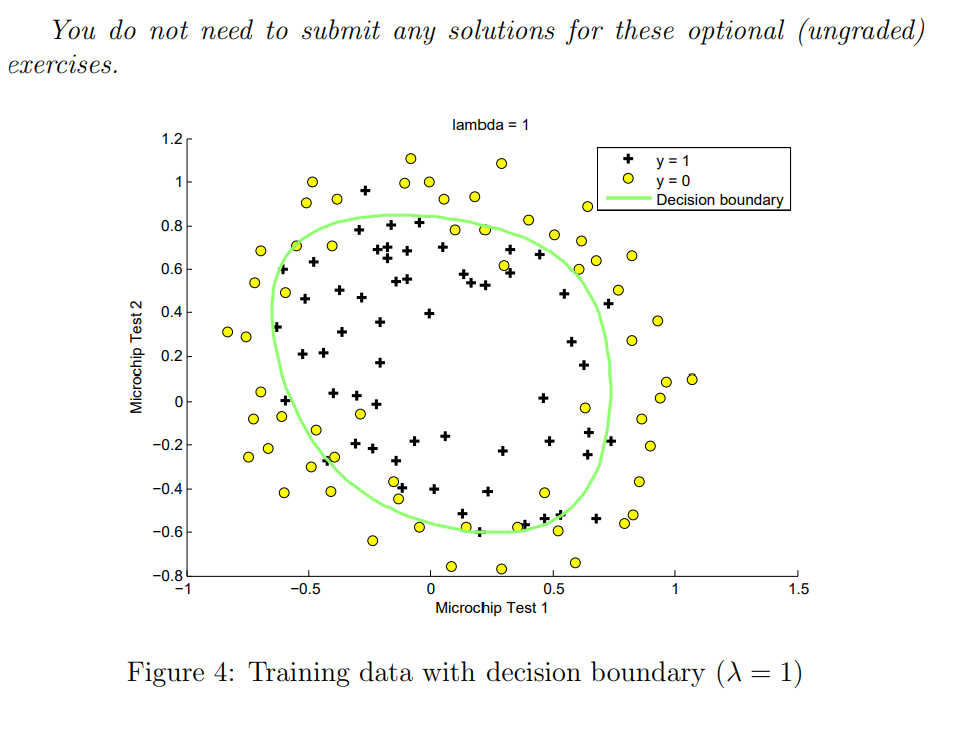
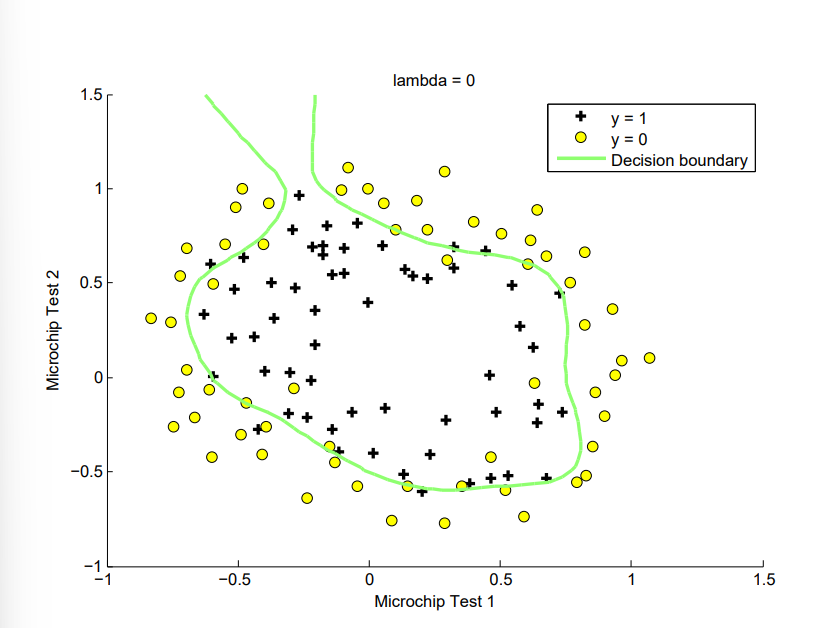
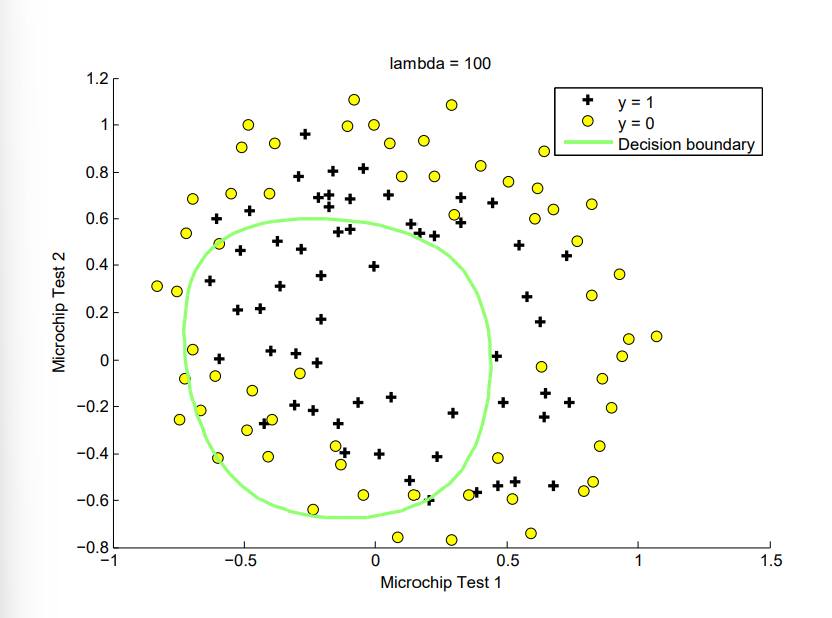

In [ ]:
ex2_reg()

In [ ]:
ex2_reg_0()

In [ ]:
ex2_reg_100()